#Basic Correlation

In [ ]:
#Import Packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#1000 random intgers between 0 and 50
x=np.random.randint(0,50,1000)

In [ ]:
#Positive Correlation with some noise
y_pos = x+ np.random.normal(0,10,1000)

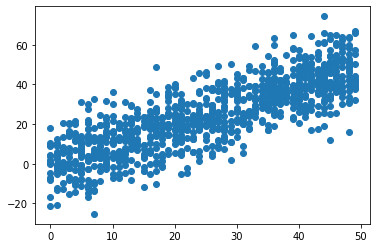

In [ ]:
plt.scatter(x, y_pos)

In [ ]:
#We can calculate r (and the p-value) using the pearsonr method
from scipy.stats import pearsonr
pearsonr(x,y_pos)

(0.8162953408973396, 4.170756073597241e-240)

In [ ]:
#You can create a correlation matrix with numpy and pandas
# |x,x|x,y|
# |y,x|y,y|
np.corrcoef(x,y_pos)

array([[1.        , 0.81629534],
       [0.81629534, 1.        ]])

In [ ]:
#We can do this with pandas as well
df = pd.DataFrame({'x':x, 'y': y_pos})
df.corr()

,x,y
x,1.000000,0.816295
y,0.816295,1.000000


array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7fed3ec74700>,
      dtype=object)

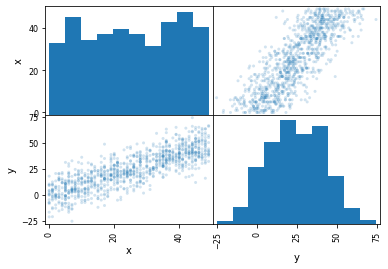

In [ ]:
#We can use a scatter matrix to visualize this
pd.plotting.scatter_matrix(df, alpha=0.2)

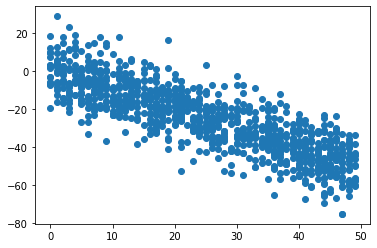

In [ ]:
y_neg = -x+np.random.normal(0,10,1000)
plt.scatter(x,y_neg)

In [ ]:
pearsonr(x,y_neg)

(-0.8371540878283641, 9.21669640172621e-264)

In [ ]:
x= np.random.randint(0,50,1000)
y=np.random.normal(0,50,1000)

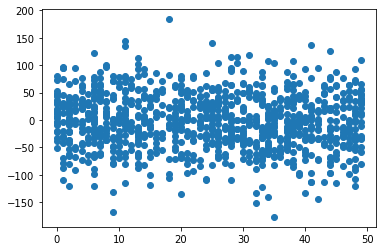

In [ ]:
plt.scatter(x,y)

In [ ]:
pearsonr(x,y)

(-0.07794898281589098, 0.013677154592933123)

# P-Value and Statistical Inference

Let use Python to bring in some data and calculate the p-value for a given Null Hypothesis

In [ ]:
na_values = [' ','NaN','N/A']
churn = pd.read_csv('https://gitlab.com/CEADS/DrKerby/python/raw/master/churn.txt',na_values=na_values)
churn.head()

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


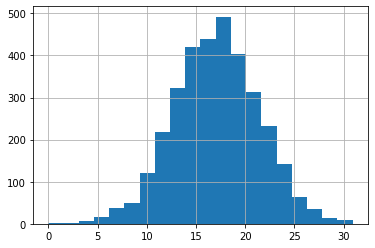

In [ ]:
churn['Eve Charge'].hist(bins=20)

In [ ]:
#For this purposes of this lecture this churn dataset will be our population
#Let take a quick look at the average value of this data
mu = churn['Eve Charge'].mean()
mu

17.083540354035403

So based on this mean, our null hypothesis will be that mu will be the average for a sample of the data. Our alternate hypothesis is that mu will not be the average value (17.08)

In [ ]:
#Take a sample of 100 points from the dataset
sample = churn.sample(n=100, replace=True)#Ensure this is done randomly
sample.head()

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
2374,WY,157,415,348-9938,yes,no,0,180.4,123,30.67,...,98,16.49,227.3,88,10.23,8.4,5,2.27,0,False.
3177,NM,84,408,419-9713,no,yes,41,153.9,102,26.16,...,117,11.96,217.7,101,9.80,12.8,5,3.46,1,False.
1193,NM,119,415,352-5118,yes,yes,15,160.0,95,27.20,...,110,17.81,82.3,107,3.70,8.7,5,2.35,5,True.
666,OR,120,415,368-8283,no,no,0,252.0,120,42.84,...,106,12.77,151.8,96,6.83,9.6,1,2.59,2,False.
2005,NY,119,415,343-1458,no,no,0,133.4,102,22.68,...,71,17.39,196.9,103,8.86,11.1,7,3.00,1,False.


In [ ]:
#Check the mean of our sample
x_bar = sample['Eve Charge'].mean()
x_bar


17.1298

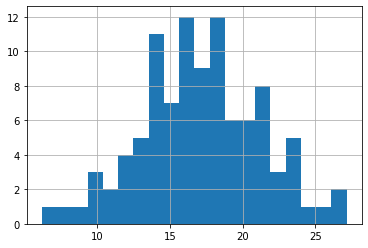

In [ ]:
#The means are fairly close
#Check the distribution of the data
sample['Eve Charge'].hist(bins=20)

The behavior of this data is a bit a bit different than our entire dataset. Let's take the mean of several samples of our data. We will also calculate the t-value for our dataset.

In [ ]:
#A t-test can only be done when comparing two groups of data.
#The formula we will use to calculate our t-value is t = (x_bar-mu)/(s/sqrt(n))
x_bar=[]
t_value=[]
for i in range(3000):
  sample =churn.sample(n=100, replace=True)
  x_bar.append(sample['Eve Charge'].mean())
  t_value.append((sample['Eve Charge'].mean()-mu)/(sample['Eve Charge'].std()/10))

(array([  2.,  11.,  27.,  45.,  79., 121., 191., 284., 337., 385., 365.,
        340., 289., 229., 146.,  75.,  47.,  15.,   9.,   3.]),
 array([15.6722  , 15.812005, 15.95181 , 16.091615, 16.23142 , 16.371225,
        16.51103 , 16.650835, 16.79064 , 16.930445, 17.07025 , 17.210055,
        17.34986 , 17.489665, 17.62947 , 17.769275, 17.90908 , 18.048885,
        18.18869 , 18.328495, 18.4683  ]),
 <a list of 20 Patch objects>)

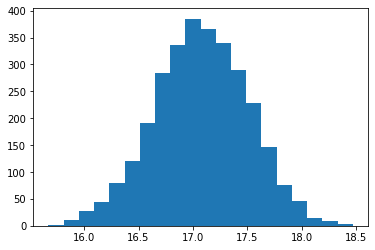

In [ ]:
#Visualize x_bar
plt.hist(x_bar, bins=20)

(array([  3.,  16.,  25.,  53.,  92., 117., 201., 301., 350., 386., 351.,
        326., 300., 203., 139.,  69.,  42.,  16.,   7.,   3.]),
 array([-3.24403114, -2.91800978, -2.59198842, -2.26596706, -1.93994571,
        -1.61392435, -1.28790299, -0.96188163, -0.63586028, -0.30983892,
         0.01618244,  0.3422038 ,  0.66822516,  0.99424651,  1.32026787,
         1.64628923,  1.97231059,  2.29833194,  2.6243533 ,  2.95037466,
         3.27639602]),
 <a list of 20 Patch objects>)

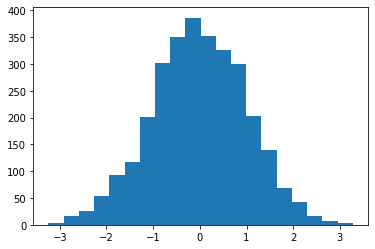

In [ ]:
#Visualize the t-value
plt.hist(t_value, bins=20)

Now Scipy has Point Probablity Function which we can use to calculate the critical value. This pretty is close to our test statistic formula.

In [ ]:
#A 95% Confidence interval (a=5%) is going to take the value of t
#at either the +/- 2.5% tails. We will prove of disprove that 95% of the
#distrubution is between +/- t-critical value
from scipy.stats import t
p=0.975 #One sided => 95% CI
df = 99 #n-1
t_critical = t.ppf(p,df)
t_critical

1.9842169515086827

Let's compare to a t table.

Looking at the table we see that the p-value is 0.05 (two tailed). If it was single tailed it would just be half of this. Since this is not less than our CI we cannot reject the null hypothesis.  

P-Value is very conisideration when performing statistical analysis. The U.S Census uses the following rules for p-values:


1.   P-Values below 0.01 consitutue strong evidence against our null.
2.   P-Values between 0.01 and 0.05 consititute moderate evidence against our null.
3. P-Values between 0.05 and 0.1 consitutue weak evidence against our null.

